In [1]:
import pickle
import polars as pl
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from scipy.interpolate import griddata
import seaborn as sns
from UnifacDortmund import UnifacDortmund
from PhaseCalculation import CalculateComps as cc

In [49]:
group_contribution = pl.read_csv("SensitivityAnalysis/data/sensitivity_group_contribution_et.csv")
MW = pl.read_csv("SensitivityAnalysis/data/sensitivity_MW_et.csv")
coeffs = pl.read_csv("SensitivityAnalysis/data/sensitivity_params_et.csv")

In [50]:
group_contribution

FAME/FAEE,GLYCEROL,ALCOHOL,OIL,DAG,MAG,ACID,H2O,Group,Stat
f64,f64,f64,f64,f64,f64,f64,f64,str,str
0.0,1.0,0.0,1.0,1.0,1.0,0.0,0.0,"""Cottonseed""","""q25"""
12.888552,2.0,1.0,40.665655,27.777104,14.888552,12.888552,0.0,"""Cottonseed""","""q25"""
2.0,0.0,1.0,3.0,2.0,1.0,1.0,0.0,"""Cottonseed""","""q25"""
1.273453,0.0,0.0,3.82036,2.546907,1.273453,1.273453,0.0,"""Cottonseed""","""q25"""
0.0,3.0,1.0,0.0,0.0,0.0,0.0,0.0,"""Cottonseed""","""q25"""
…,…,…,…,…,…,…,…,…,…
1.453942,0.0,0.0,4.361825,2.907883,1.453942,1.453942,0.0,"""Sesame""","""max"""
0.0,3.0,1.0,0.0,0.0,0.0,0.0,0.0,"""Sesame""","""max"""
1.0,0.0,0.0,3.0,2.0,1.0,0.0,0.0,"""Sesame""","""max"""


In [51]:
MW

group,stat,MW_FAME/FAEE,MW_Glycerol,MW_Alcohol,MW_Oil,MW_DAG,MW_MAG,MW_FA,MW_H2O
str,str,f64,f64,f64,f64,f64,f64,f64,i64
"""Linoleic""","""min""",322.0,92.09,46.07,920.0,627.0,334.0,280.0,18
"""Linoleic""","""q25""",322.0,92.09,46.07,920.0,627.0,334.0,280.0,18
"""Linoleic""","""median""",322.0,92.09,46.07,920.0,627.0,334.0,280.0,18
"""Linoleic""","""q75""",322.0,92.09,46.07,920.0,627.0,334.0,280.0,18
"""Linoleic""","""max""",322.0,92.09,46.07,920.0,627.0,334.0,280.0,18
…,…,…,…,…,…,…,…,…,…
"""Triolein""","""q25""",324.0,92.09,46.07,926.0,631.0,336.0,282.0,18
"""Triolein""","""median""",324.0,92.09,46.07,926.0,631.0,336.0,282.0,18
"""Triolein""","""q75""",324.0,92.09,46.07,926.0,631.0,336.0,282.0,18


In [52]:
coeffs

group,stat,m,n,p,b
str,str,f64,f64,f64,i64
"""Linoleic""","""min""",12.0,2.0,0.0,1
"""Linoleic""","""q25""",12.0,2.0,0.0,1
"""Linoleic""","""median""",12.0,2.0,0.0,1
"""Linoleic""","""q75""",12.0,2.0,0.0,1
"""Linoleic""","""max""",12.0,2.0,0.0,1
…,…,…,…,…,…
"""Triolein""","""q25""",14.0,1.0,0.0,1
"""Triolein""","""median""",14.0,1.0,0.0,1
"""Triolein""","""q75""",14.0,1.0,0.0,1


In [53]:
def surface_plot(X, Y, Z, title, x_label, y_label, z_label, bar_label):
    # Create a grid for interpolation
    X_grid = np.linspace(min(X), max(X), 50)
    Y_grid = np.linspace(min(Y), max(Y), 50)
    X_mesh, Y_mesh = np.meshgrid(X_grid, Y_grid)

    # Interpolate Z values onto the grid
    points = np.column_stack((X, Y))
    FAME_comp_grid = griddata(points, Z, (X_mesh, Y_mesh), method='linear')

    # Create a new figure
    fig = plt.figure(figsize=(12, 10))
    ax = fig.add_subplot(111, projection='3d')

    # Create surface plot
    surf = ax.plot_surface(X_mesh, Y_mesh, FAME_comp_grid, 
                        cmap='magma', 
                        edgecolor='none', 
                        alpha=0.8)


    # Add a color bar
    fig.colorbar(surf, ax=ax, shrink=0.5, aspect=5, label=bar_label)

    # Add labels with your requested arrangement
    ax.set_xlabel(x_label)
    ax.set_ylabel(y_label)
    ax.set_zlabel(z_label, labelpad=20)
    ax.set_title(title)
    ax.tick_params(axis='z', pad=10)  # Increase spacing for x-axis tick labels

    # Adjust the viewing angle for better visualization
    ax.view_init(elev=30, azim=45)
    ax.set_box_aspect(None, zoom=0.85)

    plt.tight_layout()
    plt.show()

#### 1. Parametros UNIFAC Dortmund

In [54]:
params = np.loadtxt(r"C:\Juan\Maestría\Code\oleosim\Evaluation\Stochastic_optimization\GA\UDortmundParamsGARun1.out")

In [55]:
params
A = params[0:30]
B = params[30:60]
C = params[60:90]
    
GIP = cc.define_GIP(A, B, C)

thermo_model = UnifacDortmund

#### 2. Biodiesel, Glycerol, Alcohol

In [9]:
def analysis_one(global_comps, MW, v, T):
    
    return (cc.calculate_comps(data=global_comps, v=v, data_MW=MW, 
                         temperature=T, thermo_model=thermo_model, GIP=GIP))

In [10]:
global_comps = np.array([0.4, 0.4, 0.2, 0, 0, 0, 0, 0]).reshape(1, 8)
T = np.linspace(283.15, 353.15, 50)
groups = group_contribution.group_by(["Group", "Stat"])

##### 2.1 UNIFAC Dortmund

In [11]:
results_list = []
comp_list = []

for name, data in groups:

    MW_loop = MW.filter(
        (pl.col("group") == name[0]) & (pl.col("stat") == name[1])
    ) 
    
    data = data.drop(["Group", "Stat"]).to_numpy()
    MW_loop = MW_loop.drop(["group", "stat"]).to_numpy().reshape(8)
    comp_list.append(name[0])
     
    for temperature in T:
       comps = analysis_one(global_comps, MW_loop, data, temperature) 
       comps = np.append(comps, temperature)
       comps = np.append(comps, MW_loop[0])
       results_list.append(comps)
       
       

results_total = np.vstack(results_list) 




c:\Juan\Maestría\Code\oleosim\PhaseCalculation\predict_comps.py:156: RuntimeWarning: overflow encountered in divide
  Ki = np.clip(gamma_light / gamma_heavy, 1e-6, 1e6)


In [12]:
results_total
filtered_results = results_total[results_total[:, 0] > 0.40]

In [13]:
FAME_comp = filtered_results[:,0]
FAME_MW = filtered_results[:,-1]
temperature = filtered_results[:,-2]


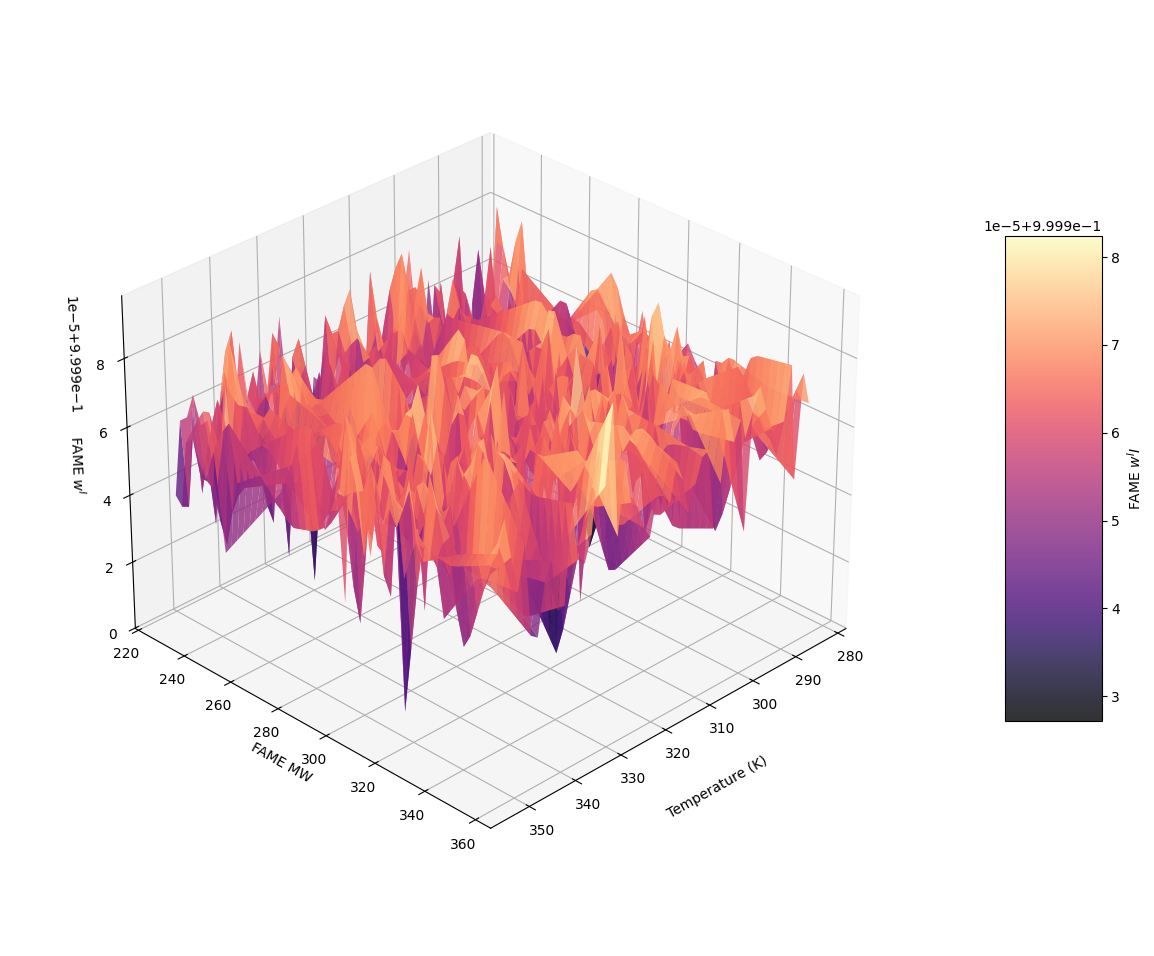

In [16]:
surface_plot(temperature, FAME_MW, FAME_comp, "", "Temperature (K)", "FAME MW", "FAME $w^I$", "FAME $w^II$")

##### 2.2 ML

In [59]:
with open('DataDriven/models/xgb_regressor_model.pkl', 'rb') as file:
    xgb_model = pickle.load(file)


In [60]:
MW_ml = MW.select(['MW_FAME/FAEE', 'MW_Oil', 'MW_DAG', 'MW_MAG', 'MW_FA']).to_numpy()

In [61]:
T_ml = T.reshape(1,50)

In [62]:
num_rows_array1 = MW_ml.shape[0]
result = np.zeros((num_rows_array1 * 50, 6))  # Will have 6 columns

# For each row in MW_ml
for i in range(num_rows_array1):
    # Get current row from MW_ml
    current_row = MW_ml[i]
    
    # Repeat this row 50 times
    repeated_rows = np.tile(current_row, (50, 1))
    
    # Add the corresponding element from T_ml as 6th column
    start_idx = i * 50
    end_idx = (i + 1) * 50
    
    # First 5 columns are the repeated row
    result[start_idx:end_idx, :5] = repeated_rows
    
    # 6th column comes from T_ml
    result[start_idx:end_idx, 5] = T_ml[0, :]

In [63]:
predict_array = np.zeros([12000, 15]) # 4900 para metanol, 12000 para etanol

In [64]:
repeated_global_comps = np.repeat(global_comps, 12000, axis=0)

In [65]:
predict_array[:,0] = result[:,-1]
predict_array[:,1] = 1
predict_array[:,2:10] = repeated_global_comps
predict_array[:,10:] = result[:,0:5]

In [66]:
predict_array_CaseI = predict_array.copy()
predict_array_CaseI[:,11:16] = 0

In [67]:
model_predictions = xgb_model.predict(predict_array_CaseI)
FAME_comp = model_predictions[:,0]

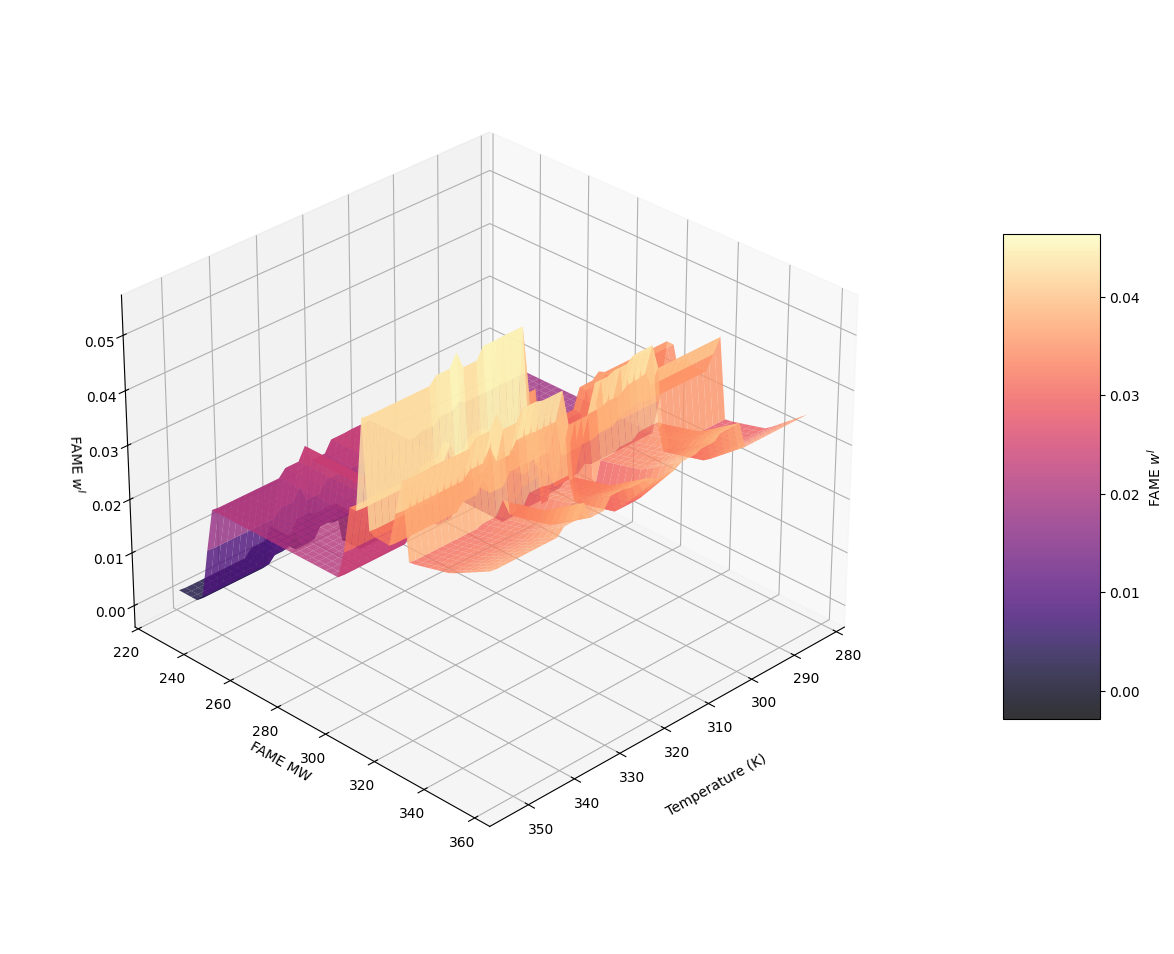

In [30]:
surface_plot(predict_array[:,0], predict_array[:,10], FAME_comp, "", "Temperature (K)", "FAME MW", "FAME $w^I$", "FAME $w^I$")

#### 3. Oil, FA, Alcohol

In [44]:
global_comps = np.array([0, 0, 0.1, 0.82, 0, 0, 0.08, 0]).reshape(1, 8)
T = np.linspace(283.15, 353.15, 50)
groups = group_contribution.group_by(["Group", "Stat"])

##### 3.1 Unifac Dortmund

In [45]:
results_list = []
comp_list = []

for name, data in groups:

    MW_loop = MW.filter(
        (pl.col("group") == name[0]) & (pl.col("stat") == name[1])
    ) 
    
    data = data.drop(["Group", "Stat"]).to_numpy()
    MW_loop = MW_loop.drop(["group", "stat"]).to_numpy().reshape(8)
    comp_list.append(name[0])
     
    for temperature in T:
       comps = analysis_one(global_comps, MW_loop, data, temperature) 
       comps = np.append(comps, temperature)
       comps = np.append(comps, MW_loop[3])
       results_list.append(comps)
       
       

results_total = np.vstack(results_list) 

In [46]:
results_total
filtered_results = results_total[results_total[:, 11] > 0.82]

In [47]:
FA_comp = results_total[:,14]
Oil_MW = results_total[:,-1]
temperature = results_total[:,-2]

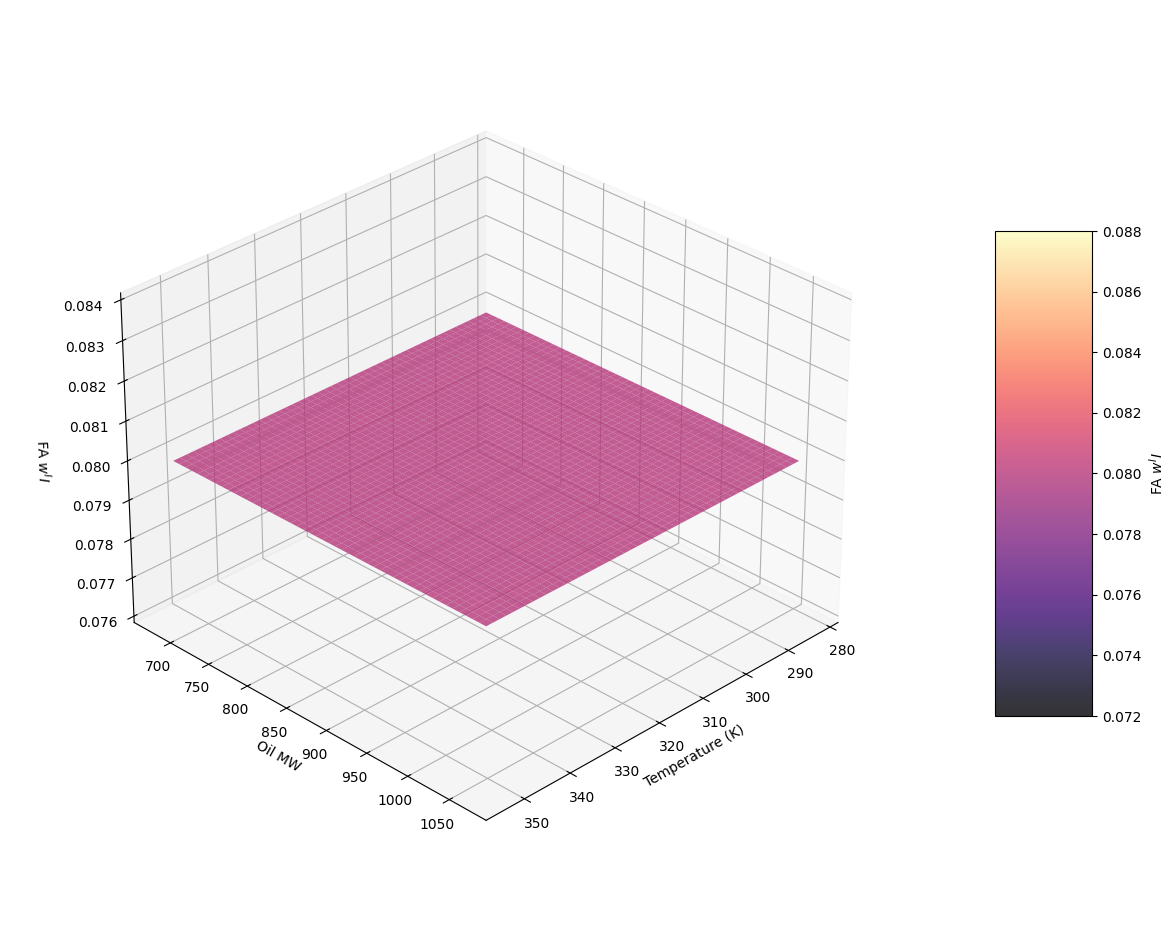

In [48]:
surface_plot(temperature, Oil_MW, FA_comp, "", "Temperature (K)", "Oil MW", "FA $w^II$", "FA $w^II$")

##### 3.2 ML

In [68]:
repeated_global_comps = np.repeat(global_comps, 12000, axis=0)
predict_array[:,2:10] = repeated_global_comps

In [69]:
predict_array_CaseII = predict_array.copy()
predict_array_CaseII[:,10] = 0
predict_array_CaseII[:,12:16] = 0

In [70]:
model_predictions = xgb_model.predict(predict_array)
FA_comp = model_predictions[:,14]

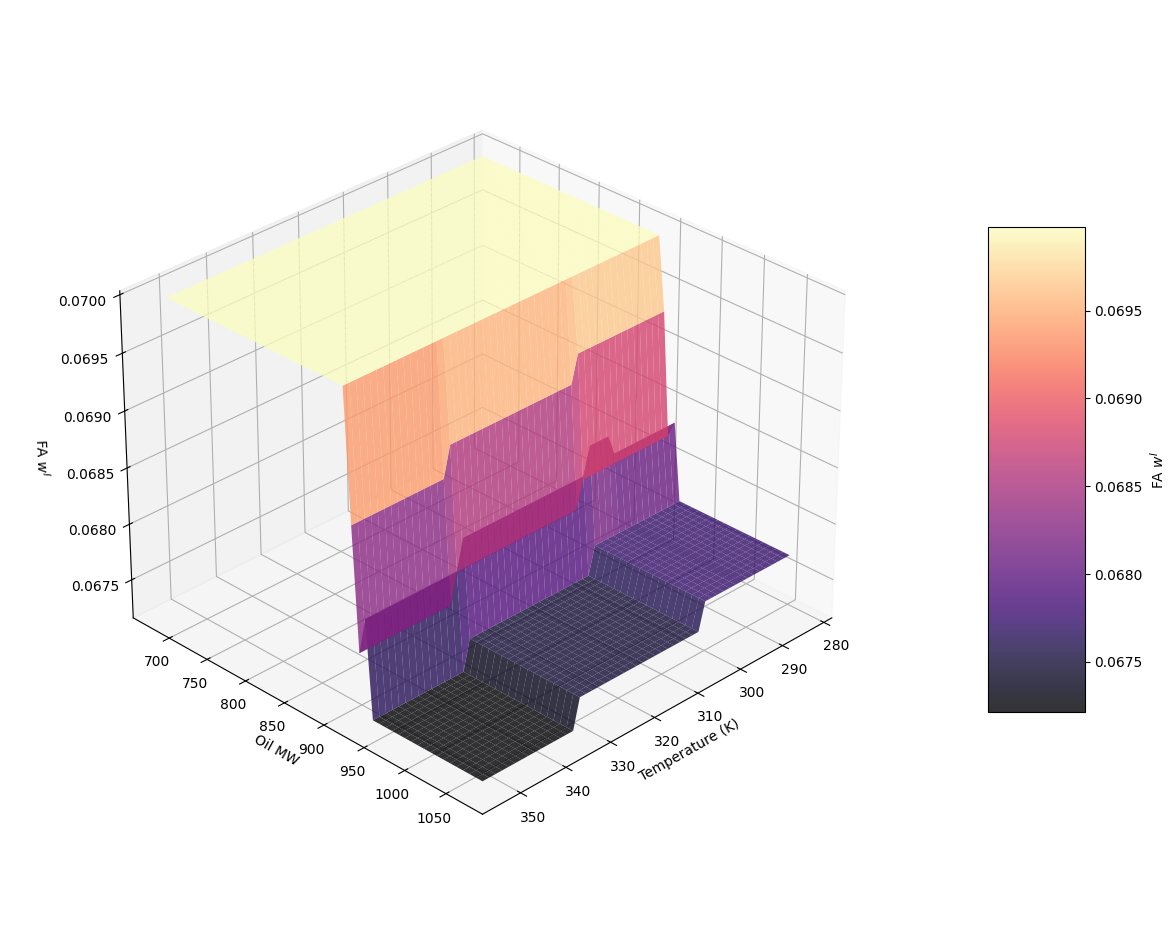

In [71]:
surface_plot(predict_array[:,0], predict_array[:,11], FA_comp, "", "Temperature (K)", "Oil MW", "FA $w^I$", "FA $w^I$")

#### 4. Biodiesel, Alcohol, Water

In [72]:
global_comps = np.array([0.8, 0, 0.1, 0, 0, 0, 0, 0.1]).reshape(1, 8)
T = np.linspace(283.15, 353.15, 50)
groups = group_contribution.group_by(["Group", "Stat"])

##### 4.1 Unifac Dortmund

In [73]:
results_list = []
comp_list = []

for name, data in groups:

    MW_loop = MW.filter(
        (pl.col("group") == name[0]) & (pl.col("stat") == name[1])
    ) 
    
    data = data.drop(["Group", "Stat"]).to_numpy()
    MW_loop = MW_loop.drop(["group", "stat"]).to_numpy().reshape(8)
    comp_list.append(name[0])
     
    for temperature in T:
       comps = analysis_one(global_comps, MW_loop, data, temperature) 
       comps = np.append(comps, temperature)
       comps = np.append(comps, MW_loop[0])
       results_list.append(comps)
       
       

results_total = np.vstack(results_list) 

In [74]:
results_total
filtered_results = results_total[results_total[:, 0] > 0.8]

In [75]:
Met_comp = filtered_results[:,10]
FAME_MW = filtered_results[:,-1]
temperature = filtered_results[:,-2]

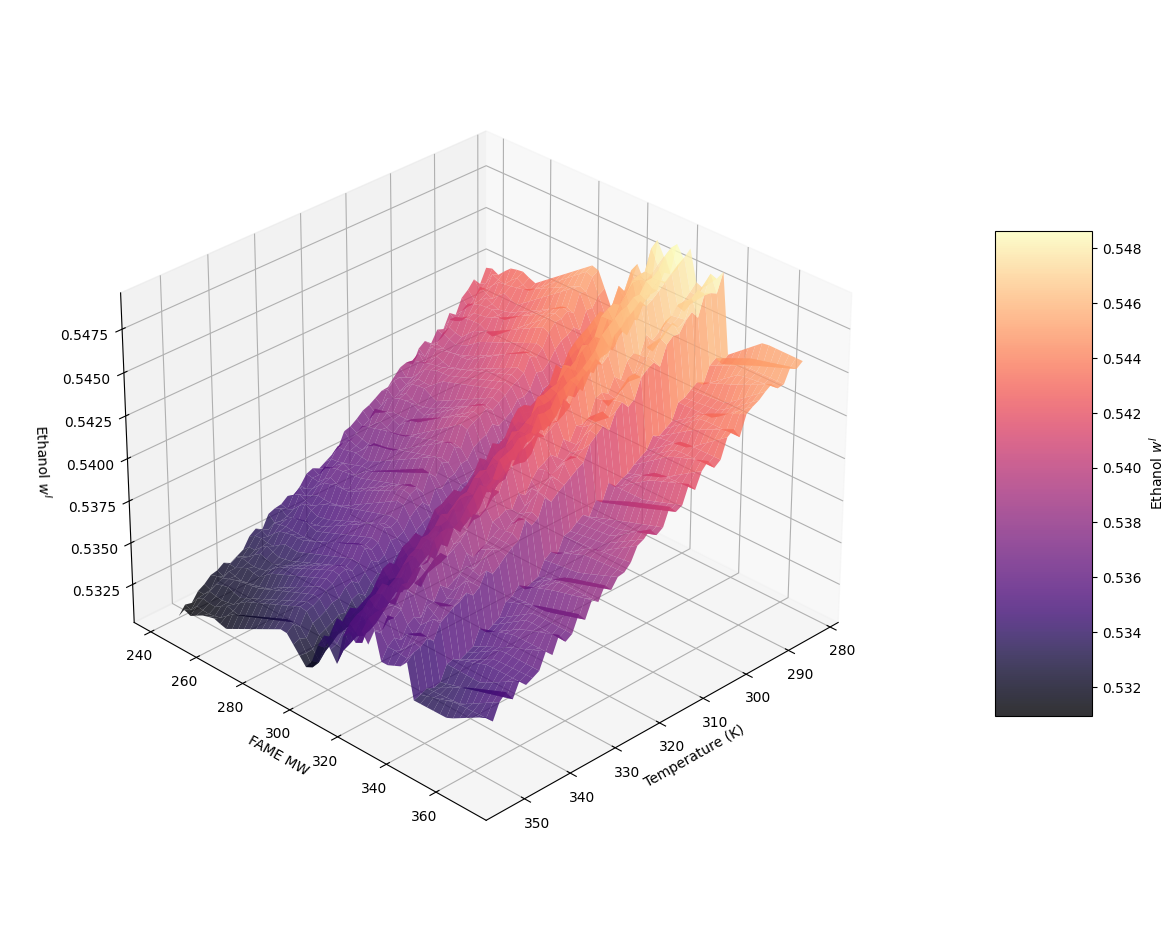

In [76]:
surface_plot(temperature, FAME_MW, Met_comp, "", "Temperature (K)", "FAME MW", "Ethanol $w^I$", "Ethanol $w^I$")

##### 4.2 ML 

In [77]:
repeated_global_comps = np.repeat(global_comps, 12000, axis=0)
predict_array[:,2:10] = repeated_global_comps

In [78]:
predict_array_CaseIII = predict_array.copy()
predict_array_CaseIII[:,11:16] = 0

In [79]:
model_predictions = xgb_model.predict(predict_array_CaseIII)
Met_comp = model_predictions[:,10]

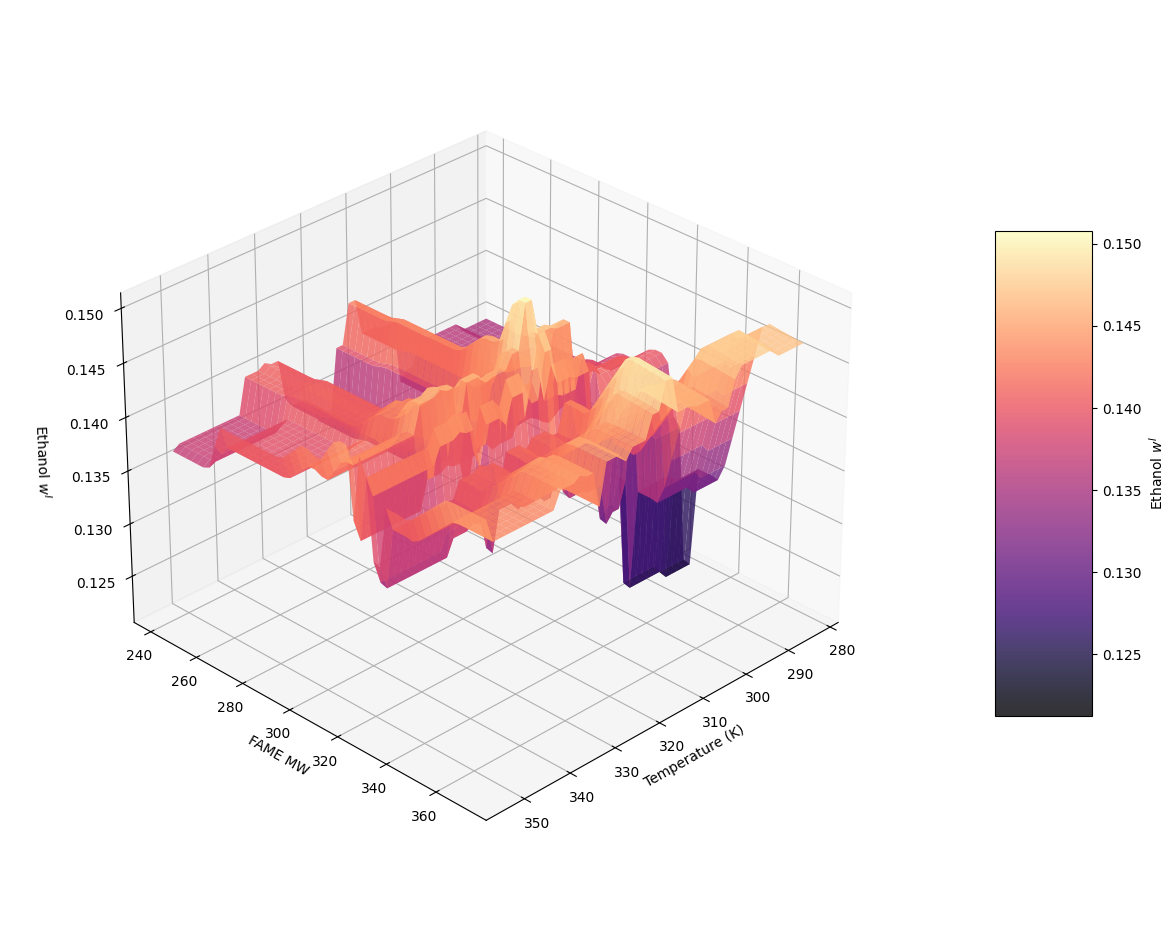

In [81]:
surface_plot(predict_array[:,0], predict_array[:,10], Met_comp, "", "Temperature (K)", "FAME MW", "Ethanol $w^I$", "Ethanol $w^I$")